[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matveyyaros/Project-activities-case-9/blob/ruslan/notebooks/03_features_preprocessing.ipynb)

# 🫐 **Анализ и подготовка данных для прогноза урожая черники**

Тетрадка закрывает этап **до обучения модели**: постановка задачи, визуальный анализ, новые признаки и гипотезы, выбор метрики, схема валидации, проверка на утечки, стратегия предобработки и сравнение способов масштабирования.

> ▶️ **Как запускать:** в Colab — меню **Среда выполнения → Выполнить все** (Ctrl+F9). Ячейки зависят друг от друга, поэтому выполнять их нужно строго сверху вниз: отдельная ячейка из середины без предыдущих выдаст `NameError`.

Итоговая модель обучается отдельно (конвейер `Ridge_Robust`: `RobustScaler → PolynomialFeatures(3) → RobustScaler → Ridge`). Здесь используется **та же схема разбиения**, что и в модели, поэтому все выводы переносятся в неё напрямую.

| Раздел | Что внутри |
|---|---|
| 1 | Постановка задачи |
| 2 | Отбор строк и столбцов, отложенная тестовая выборка |
| 3 | Визуальный анализ и инсайты |
| 4 | Выбор метрики качества |
| 5 | Схема валидации |
| 6 | Новые признаки и гипотезы |
| 7 | Стратегия предобработки: пропуски, кодирование, масштабирование |
| 8 | ★ Сравнение способов масштабирования |
| 9 | Проверка на утечки данных |
| 10 | Итоги: что передаём в модель |

## 📚 Импорты и загрузка данных

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # шум от индикатора загрузки kagglehub

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
                                   QuantileTransformer, Normalizer, PolynomialFeatures,
                                   OneHotEncoder, TargetEncoder)
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)  # предупреждения о будущих версиях sklearn

try:
    import kagglehub
except ImportError:  # в Colab kagglehub может не быть
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

SEED = 1911          # тот же seed, что в модели
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [2]:
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

KAGGLE_DATASET = "saurabhshahane/wild-blueberry-yield-prediction"
CSV_NAME = "WildBlueberryPollinationSimulationData.csv"
DATA_PATH = ROOT / "data" / "raw" / CSV_NAME
DATA_URL = ("https://raw.githubusercontent.com/matveyyaros/Project-activities-case-9/"
            "506b161/data/raw/WildBlueberryPollinationSimulationData.csv")

try:
    kaggle_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    df = pd.read_csv(next(kaggle_dir.rglob(CSV_NAME)))
    print(f"🌐 Данные скачаны с Kaggle: {KAGGLE_DATASET}")
except Exception as e:
    print(f"⚠️ Kaggle недоступен ({type(e).__name__}: {e})")
    df = pd.read_csv(DATA_PATH) if DATA_PATH.exists() else pd.read_csv(DATA_URL)
    print("📂 Данные загружены из запасного источника")
print(f"Исходная таблица: {df.shape[0]} строк × {df.shape[1]} столбцов")

🌐 Данные скачаны с Kaggle: saurabhshahane/wild-blueberry-yield-prediction
Исходная таблица: 777 строк × 18 столбцов


---
# **1. Постановка задачи** 🎯

| Вопрос | Ответ |
|---|---|
| **Бизнес-вопрос** | Какой урожай даст поле черники при заданных условиях опыления и погоды? Это нужно, чтобы планировать сбор и решать, стоит ли завозить ульи |
| **Что предсказываем** | `yield` — урожай с поля |
| **Тип задачи** | **регрессия** с учителем: цель — непрерывное число |
| **Один объект** | одна строка = **один сценарий** компьютерной симуляции опыления: размер клона, плотность четырёх видов пчёл, температура и дожди. Значение — среднее по 100 прогонам |
| **Признаки** | 7 факторов, известных **до сезона**: `clonesize`, `honeybee`, `bumbles`, `andrena`, `osmia`, `AverageOfUpperTRange`, `RainingDays` |
| **Ограничение** | данные синтетические, с дискретной сеткой значений (2–5 уровней у каждого фактора) — модель надёжна только внутри этой сетки |

---
# **2. Отбор строк и столбцов, отложенная тестовая выборка** ✂️

Сначала делаем только то, что **не использует целевую переменную**, — и сразу откладываем тест. Весь анализ дальше идёт только на обучающей части.

**Столбцы** (решения из EDA):
- `Row#` — номер строки, не свойство поля → удаляем;
- 5 дублей температуры и `AverageRainingDays` — почти точные копии `AverageOfUpperTRange` и `RainingDays` (корреляция ≈ 1) → удаляем;
- `fruitset`, `fruitmass`, `seeds` — измеряются **во время сбора урожая**, до сезона их нет → **утечка цели**, удаляем (подробно в разделе 9).

**Строки:** 18 строк особого блока вне основной сетки (`clonesize` = 10, 20, 40, плотность медоносных пчёл до 18 при обычных 0–0.75). Правило отбора — по значению признака `clonesize`, без цели, поэтому его можно применить и к новым данным.

In [3]:
FEATURES = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "AverageOfUpperTRange", "RainingDays"]
LEAKY = ["fruitset", "fruitmass", "seeds"]
TARGET = "yield"
GRID_CLONES = [12.5, 25, 37.5]

special = df[~df["clonesize"].isin(GRID_CLONES)]
print(f"Особый блок: {len(special)} строк, clonesize = {sorted(special['clonesize'].unique())}, "
      f"honeybee до {special['honeybee'].max()}")

data = df[df["clonesize"].isin(GRID_CLONES)].reset_index(drop=True)[FEATURES + LEAKY + [TARGET]]
print(f"Основная сетка: {len(data)} строк")

Особый блок: 18 строк, clonesize = [np.float64(10.0), np.float64(20.0), np.float64(40.0)], honeybee до 18.43
Основная сетка: 759 строк


### 2.1. Почему убираем 18 строк особого блока

Основные 759 строк — это **сетка**: у каждого признака 2–5 заранее выбранных значений, перебираются их сочетания (клон 12.5 / 25 / 37.5; медоносные пчёлы 0.25 / 0.5 / 0.75; шмели 0.25 / 0.38; андрены и осмии 0.25 … 0.75; температура 58.2 / 64.7 / 71.9 / 79.0 °F; дожди 1 / 16 / 24 / 34 дня).

18 строк — отдельный эксперимент **«а что если поменять одно»**: взяли одно типичное поле (`Row#` 764) и меняли у него по одному-два параметра. Ниже — все 18 строк и то, какие их значения не встречаются в сетке.

In [4]:
grid = df[df["clonesize"].isin(GRID_CLONES)]
cols = ["Row#", "clonesize", "honeybee", "bumbles", "andrena", "osmia",
        "AverageOfUpperTRange", "RainingDays", "yield"]
block = df.loc[~df["clonesize"].isin(GRID_CLONES), cols].sort_values("Row#").reset_index(drop=True)

# что поменяли у типичного поля (Row# 764) и чего нет в основной сетке
changes = {
    759: "убрали медоносных пчёл → 0 медоносных",
    760: "убрали медоносных, диких больше → шмели 0.20, андрены 0.71",
    761: "6.64 медоносных, диких нет → в 9 раз выше максимума сетки",
    762: "18.43 медоносных, диких нет → в 25 раз выше максимума",
    763: "6.64 медоносных, диких меньше",
    764: "ничего — это само типичное поле (клон 20, 3.77 дня дождей)",
    765: "18.43 медоносных, диких меньше",
    766: "почти нет пчёл → урожай 1 638, ниже любого в сетке",
    767: "только шмели 0.585 при максимуме сетки 0.38",
    768: "только андрены",
    769: "только осмии",
    770: "нет медоносных, другая смесь диких",
    771: "нет медоносных, другая смесь диких",
    772: "клон 10 — меньше минимума сетки 12.5",
    773: "клон 40 — больше максимума сетки 37.5",
    774: "дожди 24 дня (клон и пчёлы — не из сетки)",
    775: "температура 65.6 °F — нет в сетке",
    776: "65.6 °F и 24 дня дождей",
}
block["что поменяли"] = block["Row#"].map(changes)
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(block)

,Row#,clonesize,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,RainingDays,yield,что поменяли
0,759,20.0,0.000,0.117,0.409,0.058,71.9,3.77,3923.906282,убрали медоносных пчёл → 0 медоносных
1,760,20.0,0.000,0.202,0.707,0.101,71.9,3.77,5718.408168,"убрали медоносных, диких больше → шмели 0.20, андрены 0.71"
2,761,20.0,6.640,0.000,0.000,0.000,71.9,3.77,4936.364770,"6.64 медоносных, диких нет → в 9 раз выше максимума сетки"
3,762,20.0,18.430,0.000,0.000,0.000,71.9,3.77,6131.309380,"18.43 медоносных, диких нет → в 25 раз выше максимума"
4,763,20.0,6.640,0.065,0.229,0.033,71.9,3.77,5686.121958,"6.64 медоносных, диких меньше"
5,764,20.0,0.537,0.117,0.409,0.058,71.9,3.77,4225.961314,"ничего — это само типичное поле (клон 20, 3.77 дня дождей)"
6,765,20.0,18.430,0.042,0.147,0.021,71.9,3.77,6276.410544,"18.43 медоносных, диких меньше"
7,766,20.0,0.000,0.042,0.147,0.021,71.9,3.77,1637.704022,"почти нет пчёл → урожай 1 638, ниже любого в сетке"
8,767,20.0,0.000,0.585,0.000,0.000,71.9,3.77,7575.801245,только шмели 0.585 при максимуме сетки 0.38
9,768,20.0,0.000,0.000,0.585,0.000,71.9,3.77,2605.696759,только андрены


In [5]:
# Что будет, если оставить блок: модель коллег на всех 777 строках, тот же split и seed.
# Это иллюстрация решения; само правило отбора (по clonesize) урожай не использует.
from sklearn.metrics import r2_score

def r2_on(frame):
    tr, te = train_test_split(frame, test_size=0.2, random_state=SEED)
    m = make_pipeline(RobustScaler(), PolynomialFeatures(3, include_bias=False), RobustScaler(), Ridge(alpha=0.5))
    m.fit(tr[FEATURES], tr[TARGET])
    return r2_score(te[TARGET], m.predict(te[FEATURES]))

print(f"R² на тесте с блоком  (777 строк): {r2_on(df):.2f}")
print(f"R² на тесте без блока (759 строк): {r2_on(df[df['clonesize'].isin(GRID_CLONES)]):.2f}")
print(f"Куб max honeybee: блок {block['honeybee'].max()**3:,.0f} против сетки {grid['honeybee'].max()**3:.2f}")

R² на тесте с блоком  (777 строк): -3.66
R² на тесте без блока (759 строк): 0.96
Куб max honeybee: блок 6,260 против сетки 0.42


**Общее для всех 18:** размер клона 10, 20 или 40 — такого нет ни в одной строке сетки. У большинства вне сетки ещё и дожди (3.77 дня).

**Пять причин убрать блок:**
1. **Другой эксперимент.** Сетка отвечает на вопрос «как всё влияет вместе», блок — «что будет, если у одного поля поменять одну вещь». Смешивать их — как сложить в одну таблицу два опроса с разными вопросами.
2. **Каждая ситуация встречается один раз.** 18.43 медоносных пчёл — две строки, клон 40 — одна. По одной строке модель ничему не научится, а подстраиваться под неё будет.
3. **Значения далеко за пределами сетки.** 18 ульев против максимума 0.75, полное отсутствие пчёл против минимума 0.25. Для полиномов это опасно: куб от 18.43 ≈ 6 260, куб от 0.75 ≈ 0.42 — одна строка «перетягивает» всю модель.
4. **Это видно в цифрах.** Модель коллег на всех 777 строках получает на тесте R² ≈ **−3.66** — хуже, чем всегда предсказывать среднее. Без блока — R² ≈ **0.96**.
5. **Отбор без подглядывания в урожай.** Строки отбираются только по `clonesize`, поэтому утечки нет, и то же правило применимо к новым данным.

⚠️ **Цена решения:** модель не умеет отвечать на вопросы блока («что будет без пчёл», «что даст 18 ульев», «клон 40»). Её прогнозы надёжны только внутри сетки — это ограничение стоит прямо назвать в отчёте.

In [6]:
# Отложенный тест — та же схема, что в модели: 20 %, random_state = 1911
train, test = train_test_split(data, test_size=0.2, random_state=SEED)

assert set(train.index).isdisjoint(test.index), "строки теста попали в обучение"
assert train[FEATURES].merge(test[FEATURES], how="inner").empty, "одинаковые сценарии в train и test"

X, y = train[FEATURES], train[TARGET]
print(f"Обучение: {len(train)} строк | Тест: {len(test)} строк — тест дальше не используется")

Обучение: 607 строк | Тест: 152 строк — тест дальше не используется


🔒 **С этого места `test` не открываем.** Все графики, гипотезы и сравнения — только на `train` (607 строк). Тест нужен один раз — для финальной оценки уже обученной модели. Так решения о признаках и предобработке не «подсматривают» в тест.

---
# **3. Визуальный анализ и инсайты** 📊
## 3.1 Целевая переменная

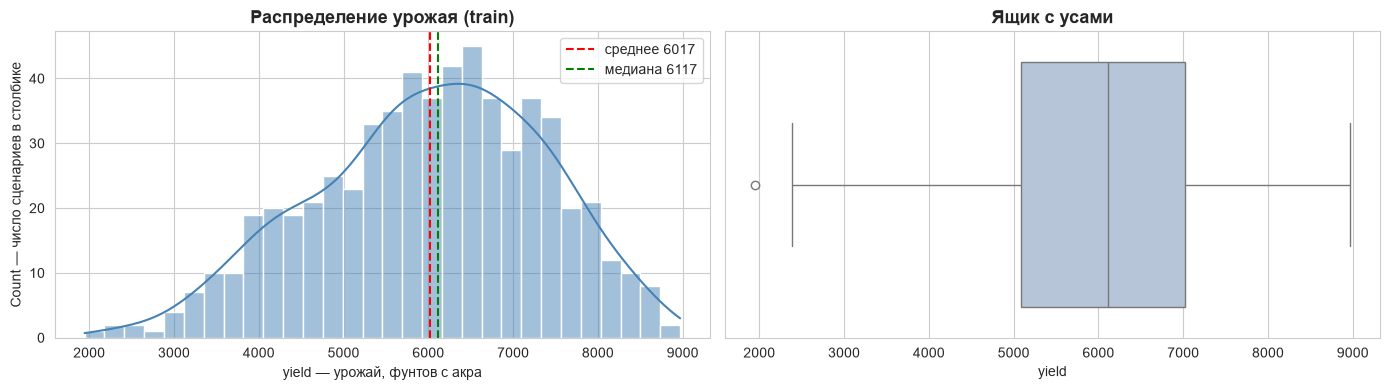

,count,mean,std,min,25%,50%,75%,max
yield,607.0,6017.0,1348.0,1946.0,5086.0,6117.0,7024.0,8969.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(y, bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(y.mean(), color="red", linestyle="--", label=f"среднее {y.mean():.0f}")
axes[0].axvline(y.median(), color="green", linestyle="--", label=f"медиана {y.median():.0f}")
axes[0].set_title("Распределение урожая (train)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Count — число сценариев в столбике")
axes[0].set_xlabel("yield — урожай, фунтов с акра")
axes[0].legend()
sns.boxplot(x=y, color="lightsteelblue", ax=axes[1])
axes[1].set_title("Ящик с усами", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
y.describe().round(0).to_frame().T

**Как читать графики**

*Левый — гистограмма.*
- Ось X (`yield`) — урожай. Весь диапазон разбит на 30 равных отрезков шириной ≈ 235 фунтов с акра, каждый отрезок — один столбик.
- Ось Y (**`Count`**) — **сколько строк (сценариев) из обучающей части попало в этот отрезок**. Например, столбик высотой 45 около 6 500 значит: в 45 сценариях урожай оказался примерно от 6 400 до 6 650. Сумма высот всех столбиков равна 607 — числу строк в `train`.
- Синяя плавная линия — сглаженная форма того же распределения (KDE), чтобы видеть общую «горку» без зубцов отдельных столбиков.
- Красный и зелёный пунктир — среднее и медиана (значение, которое делит сценарии пополам).

*Правый — ящик с усами.* Ящик — середина данных: половина сценариев с урожаем примерно от 5 100 до 7 000; черта внутри — медиана. Усы тянутся до самых дальних «обычных» значений, точка слева — сценарий, который заметно ниже остальных.

*Таблица под графиками.* `count` = 607 — сколько всего строк в `train` (это то же, что сумма высот столбиков); `mean` — среднее; `std` — типичное отклонение от среднего; `min`/`max` — крайние значения; `25%`, `50%`, `75%` — урожай, ниже которого четверть, половина и три четверти сценариев (`50%` — медиана).

**Что видно:**
- Урожай от ~1 950 до ~8 970, **нулей и отрицательных значений нет**, среднее ≈ медиане.
- Слабый «хвост» влево: неудачные сценарии (много дождей + жара) дают урожай вдвое ниже обычного. Это не ошибки, а реальные плохие сезоны — удалять их нельзя.
- Эти свойства понадобятся при выборе метрики (раздел 4).

## 3.2 Как каждый фактор влияет на урожай

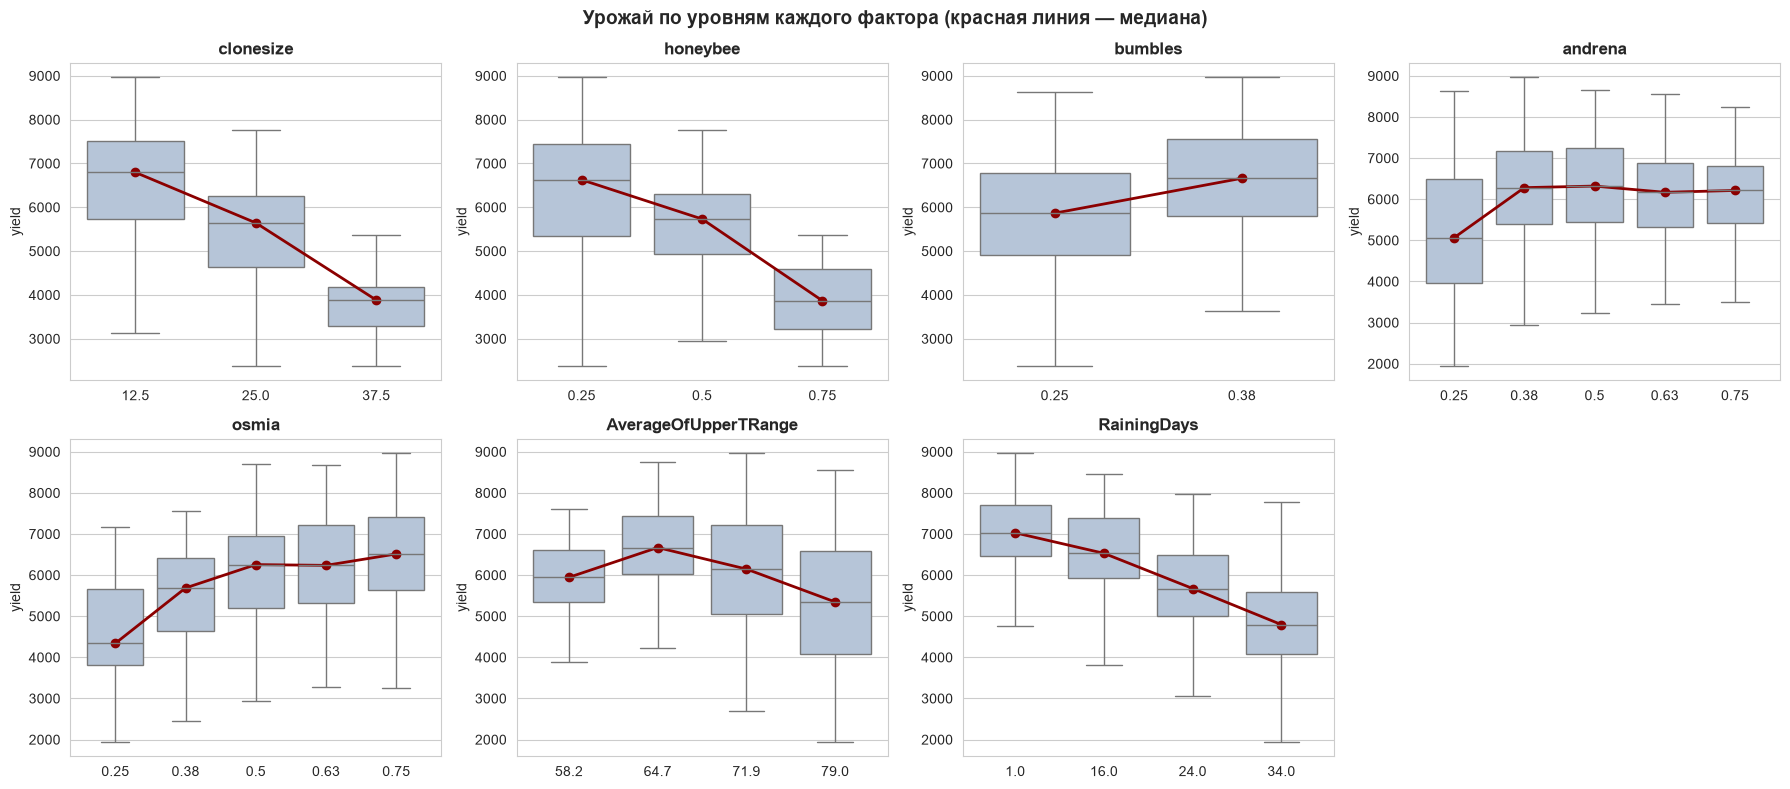

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=train, x=col, y=TARGET, color="lightsteelblue", ax=ax, showfliers=False)
    med = train.groupby(col)[TARGET].median().values
    ax.plot(range(len(med)), med, "o-", color="darkred", linewidth=2)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Урожай по уровням каждого фактора (красная линия — медиана)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 💡 Инсайты
- **Температура — горб, а не прямая.** Лучший урожай при умеренной температуре (≈ 65 °F), и холоднее, и жарче — хуже. Линейная модель такую форму не увидит → **гипотеза 1**.
- **Дожди — падение ускоряется** с ростом числа дождливых дней → **гипотеза 2**.
- **Осмии и андрены — рост с насыщением**: основной прирост на первом шаге плотности, дальше почти плато → **гипотеза 4**.
- **Клон**: чем крупнее клон, тем ниже урожай.
- **Медоносные пчёлы** выглядят почти бесполезными или даже вредными — это ловушка (раздел 3.4).

## 3.3 Взаимосвязи: линейная и ранговая корреляция

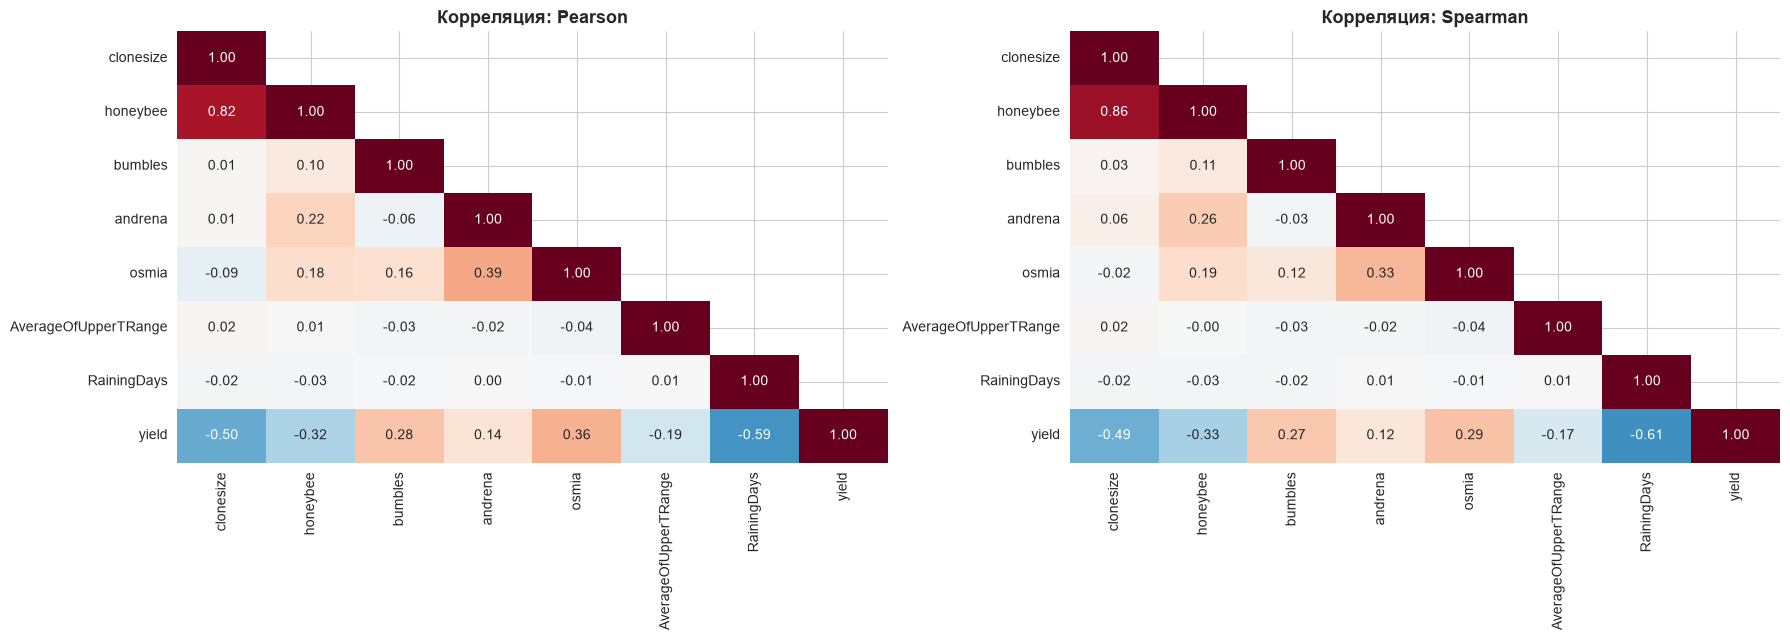

In [9]:
cols = FEATURES + [TARGET]
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = train[cols].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax, cbar=False)
    ax.set_title(f"Корреляция: {method.capitalize()}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 💡 Инсайты
- Сильнее всего с урожаем связаны **дожди** (−0.6) и **размер клона** (−0.5), затем **осмии** (+0.3…0.4), **медоносные пчёлы** (−0.3) и **шмели** (+0.3).
- **Температура** почти не коррелирует с урожаем ни по Пирсону, ни по Спирмену, хотя на графике 3.2 эффект большой. Обе меры ищут **монотонную** связь, а у температуры горб: рост и падение взаимно гасятся. Вывод: **низкая корреляция ≠ слабый признак** — нужен признак, описывающий оптимум.
- Между факторами корреляции в основном около нуля, **кроме двух пар**: `honeybee` — `clonesize` (0.82) и `andrena` — `osmia` (0.39). Первая пара — источник ловушки из раздела 3.5. Погода с пчёлами и клоном не связана совсем — её эффект можно оценивать отдельно.

## 3.4 Совместное влияние дождей и температуры

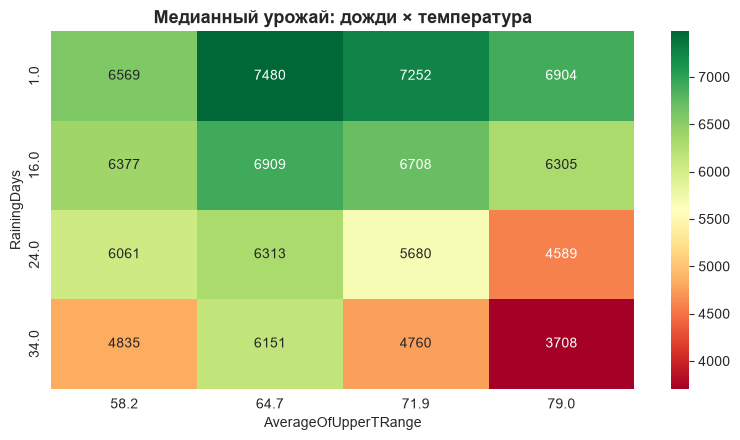

Потеря урожая от минимума к максимуму дождей при каждой температуре:
AverageOfUpperTRange
58.2    1734.0
64.7    1329.0
71.9    2492.0
79.0    3196.0


In [10]:
pivot = train.pivot_table(index="RainingDays", columns="AverageOfUpperTRange", values=TARGET, aggfunc="median")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax)
ax.set_title("Медианный урожай: дожди × температура", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
loss = (pivot.iloc[0] - pivot.iloc[-1]).round(0)
print("Потеря урожая от минимума к максимуму дождей при каждой температуре:")
print(loss.to_string())

💡 **Дождь вредит сильнее в жару.** При умеренной температуре дожди отнимают меньше всего урожая, а в самую жаркую погоду — больше всего. Эффект одного фактора зависит от другого — это **взаимодействие** → **гипотеза 3**.

## 3.5 Ловушка: медоносные пчёлы

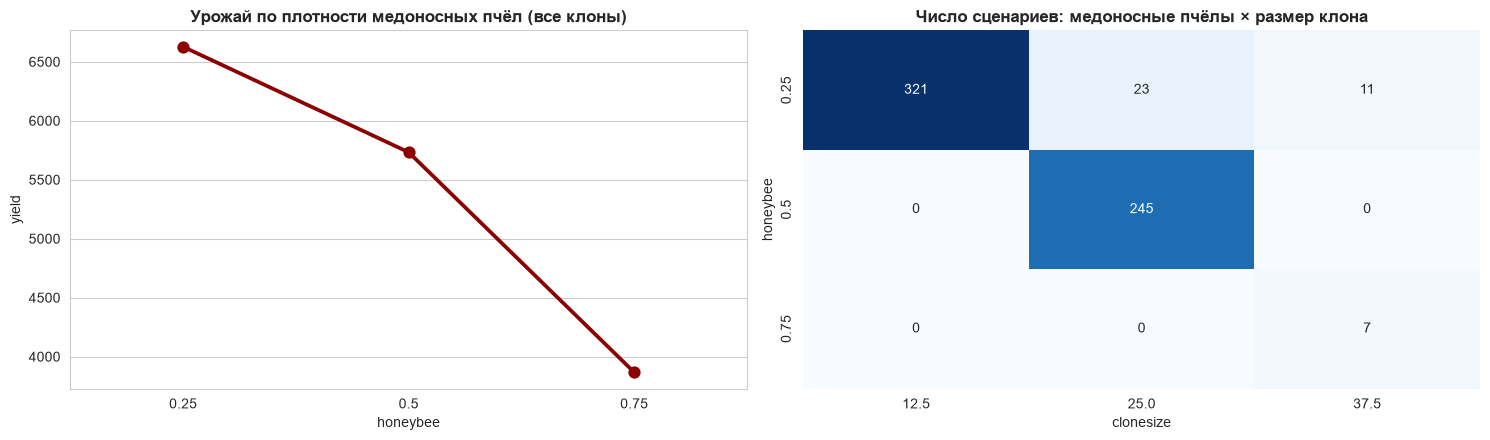

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.pointplot(data=train, x="honeybee", y=TARGET, estimator="median", errorbar=None, color="darkred", ax=axes[0])
axes[0].set_title("Урожай по плотности медоносных пчёл (все клоны)", fontsize=12, fontweight="bold")
ct = pd.crosstab(train["honeybee"], train["clonesize"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Число сценариев: медоносные пчёлы × размер клона", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

💡 Урожай падает с ростом плотности медоносных пчёл — но таблица справа показывает почему: плотность 0.5 встречается **только в клоне 25**, а 0.75 — **только в клоне 37.5**. Мы видим эффект **размера клона**, а не пчёл. Внутри клона 25 уровни медоносных пчёл к тому же связаны с плотностью диких пчёл (EDA, раздел 5.4). Связь «больше ульев → меньше урожай» — **смешение факторов**, а не причинный эффект. Для модели вывод такой: признак `honeybee` оставляем (он известен до сезона), но **его коэффициент не интерпретируем** как пользу или вред ульев.

---
# **4. Выбор метрики качества** 📏

### Основная метрика — **MAE** (средняя абсолютная ошибка)
Почему именно она для этой задачи:
1. **Понятна заказчику.** MAE измеряется в тех же единицах, что и урожай: «прогноз в среднем ошибается на N». Для планирования сбора, тары и рабочих это прямой ответ на вопрос «насколько можно доверять цифре».
2. **Цена ошибки примерно линейна.** Недобор и перебор на 200 единиц обходятся примерно одинаково (лишняя или недостающая тара и смена сборщиков), и ошибка на 400 — примерно вдвое дороже ошибки на 200. Это и есть MAE.
3. **Устойчива к отдельным сценариям.** Плохие сезоны (раздел 3.1) — редкие, но настоящие. MAE не даёт одному такому сценарию перекосить сравнение моделей.

### Вспомогательные метрики
| Метрика | Зачем нужна в этой задаче |
|---|---|
| **RMSE** | сильнее штрафует **крупные** промахи. Если RMSE заметно больше MAE — модель иногда сильно ошибается, обычно в неудачные сезоны (дожди + жара), где ошибка дороже всего |
| **R²** | доля объяснённого разброса, не зависит от единиц — удобно сравнивать с другими работами. Именно по R² подбираются гиперпараметры в модели (`GridSearchCV(scoring="r2")`) |
| **MAPE** | ошибка в процентах. Корректна, потому что урожай всегда больше нуля (минимум ≈ 1 950, раздел 3.1). Показывает, что 300 при урожае 2 000 — это хуже, чем 300 при 8 000 |

**Согласованы ли метрики между собой.** При одних и тех же данных R² = 1 − MSE / дисперсия, то есть R² и RMSE ранжируют модели **одинаково**. Ниже проверим на всех вариантах из разделов 6–8, совпадает ли ранжирование по MAE и по R²: если да — выбор R² для подбора гиперпараметров в модели не противоречит основной метрике.

---
# **5. Схема валидации** 🔁

| Элемент | Решение | Почему |
|---|---|---|
| Отложенный тест | 20 % (152 строки), `random_state=1911` | финальная честная оценка, совпадает с моделью |
| Кросс-валидация на train | `KFold(n_splits=10, shuffle=True, random_state=1911)` | та же, что в `GridSearchCV` модели; 10 частей по ~60 строк дают устойчивую оценку при 607 строках |
| Перемешивание | да | строки в файле упорядочены по плану эксперимента — без перемешивания части были бы непохожи друг на друга |
| Результат | **среднее ± стандартное отклонение по 10 фолдам** | одна цифра скрывает, насколько оценка зависит от разбиения |
| Предобработка | только внутри `Pipeline` | масштаб и прочие параметры считаются на обучающей части фолда (раздел 9) |

Все сравнения в тетрадке — на **одних и тех же 10 разбиениях**: разница между вариантами — это разница подходов, а не везение разбиения.

In [12]:
CV = KFold(n_splits=10, shuffle=True, random_state=SEED)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error",
           "R2": "r2", "MAPE": "neg_mean_absolute_percentage_error"}

def cv_scores(model, Xd, yd=y):
    """Метрики по каждому из 10 фолдов (DataFrame: строка — фолд)."""
    res = cross_validate(model, Xd, yd, cv=CV, scoring=SCORING)
    out = pd.DataFrame({k: res[f"test_{k}"] for k in SCORING})
    for k in ["MAE", "RMSE", "MAPE"]:
        out[k] = -out[k]
    out["MAPE"] *= 100
    return out

def summary(folds):
    """Среднее ± разброс по фолдам."""
    return {f"{k}": f"{folds[k].mean():.{4 if k == 'R2' else 1}f} ± {folds[k].std():.{4 if k == 'R2' else 1}f}"
            for k in folds.columns} | {"_MAE": folds["MAE"].mean(), "_R2": folds["R2"].mean()}

base_folds = cv_scores(LinearRegression(), X)
base_folds.index = [f"фолд {i+1}" for i in range(10)]
display(base_folds.round(3).T)
print("Линейная регрессия на 7 факторах:",
      {k: v for k, v in summary(base_folds).items() if not k.startswith("_")})

,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,фолд 6,фолд 7,фолд 8,фолд 9,фолд 10
MAE,445.332,543.387,523.596,565.918,536.761,460.040,460.072,454.485,488.045,542.036
RMSE,557.535,647.662,654.172,656.761,643.800,532.559,570.372,598.399,585.893,654.505
R2,0.792,0.770,0.708,0.795,0.764,0.888,0.868,0.694,0.743,0.747
MAPE,7.985,9.437,9.787,10.500,9.223,8.156,8.750,7.523,8.910,10.155


Линейная регрессия на 7 факторах: {'MAE': '502.0 ± 45.0', 'RMSE': '610.2 ± 46.8', 'R2': '0.7770 ± 0.0623', 'MAPE': '9.0 ± 1.0'}


In [13]:
fold_37 = [int((X.iloc[v]["clonesize"] == 37.5).sum()) for _, v in CV.split(X)]
print(f"Клон 37.5 в train: {(X['clonesize'] == 37.5).sum()} строк; по фолдам валидации: {fold_37}")

Клон 37.5 в train: 18 строк; по фолдам валидации: [1, 1, 2, 3, 1, 3, 6, 0, 0, 1]


- Ошибка заметно меняется от фолда к фолду — поэтому **результат всегда приводим как среднее ± разброс**, и разницу между вариантами считаем существенной, только если она больше разброса.
- Редкий клон 37.5 распределён по фолдам неравномерно (в некоторых фолдах его нет). Стратификация по `clonesize` это исправила бы, но модель использует обычный `KFold` — оставляем его, чтобы оценки здесь и в модели были сравнимы. Неравномерность отражается в разбросе по фолдам.

---
# **6. Новые признаки и гипотезы** 🔬

Каждая гипотеза — из раздела 3. Проверка: добавляем признак к 7 факторам и смотрим ошибку **линейной регрессии** на той же кросс-валидации. Линейная модель видит только прямые зависимости, поэтому полезный признак, описывающий нелинейность, сразу снижает её ошибку.

| № | Гипотеза | Признак |
|---|---|---|
| Г1 | У температуры есть оптимум (3.2, 3.3) | `temp_sq` = температура² |
| Г2 | Вред от дождей нарастает (3.2) | `rain_sq` = дождливые дни² |
| Г3 | Дождь в жару вредит сильнее (3.4) | `rain_x_temp` = дни × температура |
| Г4 | Насыщение по осмиям и андренам (3.2) | `osmia_sq`, `andrena_sq` |
| Г5 | Важна общая плотность опылителей | `wild_bees` = шмели + андрены + осмии; `bees_per_clone` = все пчёлы / размер клона |

Оптимум температуры мы **не задаём числом** (например, |T − 65|): он найден на этих же данных, это была бы подгонка. Пара «T и T²» позволяет модели найти оптимум самой.

In [14]:
def add_features(d):
    d = d.copy()
    d["temp_sq"] = d["AverageOfUpperTRange"] ** 2
    d["rain_sq"] = d["RainingDays"] ** 2
    d["rain_x_temp"] = d["RainingDays"] * d["AverageOfUpperTRange"]
    d["osmia_sq"] = d["osmia"] ** 2
    d["andrena_sq"] = d["andrena"] ** 2
    d["wild_bees"] = d["bumbles"] + d["andrena"] + d["osmia"]
    d["bees_per_clone"] = (d["wild_bees"] + d["honeybee"]) / d["clonesize"]
    return d

XF = add_features(X)   # признаки строятся по строке — без статистик по выборке, утечки нет
CANDIDATES = {"temp_sq": "Г1", "rain_sq": "Г2", "rain_x_temp": "Г3", "osmia_sq": "Г4",
              "andrena_sq": "Г4", "wild_bees": "Г5", "bees_per_clone": "Г5"}
base = summary(base_folds)

rows = []
for feat, h in CANDIDATES.items():
    s = summary(cv_scores(LinearRegression(), XF[FEATURES + [feat]]))
    rows.append({"признак": feat, "гипотеза": h,
                 "Спирмен с yield": round(XF[feat].corr(y, method="spearman"), 3),
                 "MAE": s["MAE"], "ΔMAE": round(s["_MAE"] - base["_MAE"], 1), "R²": s["R2"]})
print(f"Без новых признаков: MAE {base['MAE']}, R² {base['R2']}")
pd.DataFrame(rows).set_index("признак")

Без новых признаков: MAE 502.0 ± 45.0, R² 0.7770 ± 0.0623


,гипотеза,Спирмен с yield,MAE,ΔMAE,R²
признак,,,,,
temp_sq,Г1,-0.168,389.2 ± 29.5,-112.8,0.8622 ± 0.0436
rain_sq,Г2,-0.611,468.4 ± 44.0,-33.5,0.7972 ± 0.0629
rain_x_temp,Г3,-0.632,473.8 ± 28.9,-28.2,0.8133 ± 0.0456
osmia_sq,Г4,0.294,502.0 ± 42.2,0.0,0.7774 ± 0.0635
andrena_sq,Г4,0.120,502.7 ± 46.2,0.8,0.7760 ± 0.0620
wild_bees,Г5,0.268,502.0 ± 45.0,-0.0,0.7770 ± 0.0623
bees_per_clone,Г5,0.573,495.1 ± 45.4,-6.9,0.7822 ± 0.0648


### 💡 Итог проверки по одному признаку

| Гипотеза | Итог |
|---|---|
| Г1. Оптимум температуры | ✅ **подтверждена**, самый сильный признак: ошибка падает больше, чем на разброс по фолдам |
| Г2. Вред дождей нарастает | ✅ подтверждена |
| Г3. Дождь в жару хуже | ✅ подтверждена |
| Г4. Насыщение осмий и андрен | ❌ в такой форме нет: насыщение на графике есть, но это резкий скачок и плато, а квадрат описывает плавную параболу — ошибка не меняется |
| Г5. Сумма диких пчёл | ❌ ΔMAE = 0: это точная сумма уже имеющихся признаков, линейная модель и так умеет их сложить |
| Г5. Пчёлы на м² клона | ❌ почти ничего: корреляция с урожаем высокая, но взята из `clonesize`, который уже в модели. **Высокая корреляция ≠ полезный признак** |

## 6.1 Признаки вместе и связь с `PolynomialFeatures` модели

,признаков,MAE,RMSE,R2,MAPE
7 факторов,7,502.0 ± 45.0,610.2 ± 46.8,0.7770 ± 0.0623,9.0 ± 1.0
7 + temp_sq,8,389.2 ± 29.5,479.0 ± 33.4,0.8622 ± 0.0436,7.0 ± 0.4
7 + temp_sq + rain_sq,9,342.9 ± 34.7,438.1 ± 37.9,0.8845 ± 0.0390,6.2 ± 0.6
7 + 3 новых (Г1–Г3),10,285.0 ± 29.1,367.2 ± 29.6,0.9196 ± 0.0239,5.2 ± 0.6
PolynomialFeatures(2),35,266.0 ± 39.3,342.4 ± 43.1,0.9291 ± 0.0249,4.8 ± 0.8
PolynomialFeatures(3),119,230.7 ± 16.2,287.3 ± 18.4,0.9513 ± 0.0110,4.1 ± 0.4


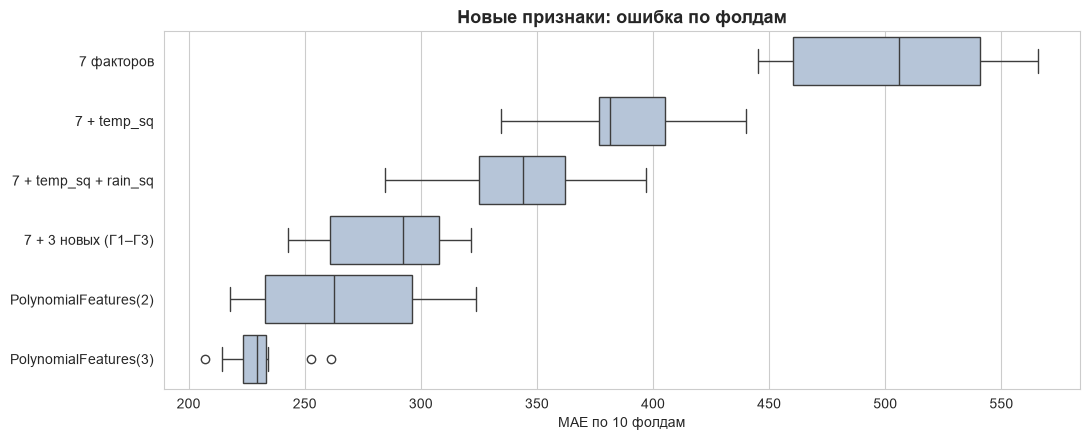

In [15]:
NEW = ["temp_sq", "rain_sq", "rain_x_temp"]
def poly_ridge(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=0.5))

variants = {
    "7 факторов": (LinearRegression(), XF[FEATURES], 7),
    "7 + temp_sq": (LinearRegression(), XF[FEATURES + NEW[:1]], 8),
    "7 + temp_sq + rain_sq": (LinearRegression(), XF[FEATURES + NEW[:2]], 9),
    "7 + 3 новых (Г1–Г3)": (LinearRegression(), XF[FEATURES + NEW], 10),
    "PolynomialFeatures(2)": (poly_ridge(2), X, 35),
    "PolynomialFeatures(3)": (poly_ridge(3), X, 119),
}
fe_folds = {name: cv_scores(m, Xd) for name, (m, Xd, _) in variants.items()}
fe_table = pd.DataFrame({name: {"признаков": n, **summary(fe_folds[name])} for name, (_, _, n) in variants.items()}).T
display(fe_table.drop(columns=["_MAE", "_R2"]))

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=pd.DataFrame({k: v["MAE"] for k, v in fe_folds.items()}), orient="h", color="lightsteelblue", ax=ax)
ax.set_xlabel("MAE по 10 фолдам")
ax.set_title("Новые признаки: ошибка по фолдам", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 💡 Что это значит для модели
- Три подтверждённых признака (Г1–Г3) снижают ошибку линейной модели **почти вдвое**, и ящики на графике не пересекаются — эффект намного больше разброса по фолдам.
- `PolynomialFeatures(3)` в модели — **автоматическое обобщение тех же гипотез**: квадраты и произведения всех пар и троек факторов. Он содержит `temp_sq`, `rain_sq`, `rain_x_temp` и ещё более сотни членов, поэтому немного точнее, но коэффициенты уже не прочитать.
- Наши гипотезы **обосновывают** выбор полиномиальных признаков в модели: нелинейность и взаимодействия в данных есть, и именно они дают основной выигрыш. А 10 признаков (7 + 3) — интерпретируемая альтернатива, почти не уступающая по точности второй степени.

---
# **7. Стратегия предобработки** 🧭

## 7.1 Пропуски

In [16]:
print("Пропусков в train по столбцам:", int(train.isna().sum().sum()))
print("Бесконечных значений:", int(np.isinf(train.select_dtypes("number")).sum().sum()))

Пропусков в train по столбцам: 0
Бесконечных значений: 0


Пропусков нет — симуляция выдаёт полную таблицу. **Заполнение не нужно**, и сравнивать способы заполнения не на чем. Если модель будут применять к полевым данным, в начало конвейера стоит поставить `SimpleImputer(strategy="median")` (медиана — потому что плотности пчёл скошены) — внутри `Pipeline`, чтобы медиана считалась только по обучающей части.

## 7.2 Кодирование
Все признаки числовые, но у каждого всего 2–5 уровней. Значит, их можно подать как числа, а можно как категории. Сравниваем три варианта на той же схеме:
- **числа** — сохраняют порядок уровней, признаков мало;
- **one-hot** — каждый уровень становится отдельным признаком, модель получает любую форму зависимости;
- **target encoding** — уровень заменяется средним урожаем на этом уровне. Это кодирование использует цель, поэтому его можно делать **только внутри фолда** (в `TargetEncoder` это встроено).

In [17]:
n_levels = sum(X[c].nunique() for c in FEATURES)
enc_variants = {
    "числа": (LinearRegression(), X, 7),
    "one-hot": (make_pipeline(OneHotEncoder(handle_unknown="ignore"), LinearRegression()), X, n_levels),
    "target encoding": (make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), LinearRegression()),
                        X.astype(str), 7),
    "числа + 3 новых": (LinearRegression(), XF[FEATURES + NEW], 10),
    "числа → PolynomialFeatures(3)": (poly_ridge(3), X, 119),
}
enc_table = pd.DataFrame({name: {"признаков": n, **summary(cv_scores(m, Xd))}
                          for name, (m, Xd, n) in enc_variants.items()}).T
enc_table.drop(columns=["_MAE", "_R2"])

,признаков,MAE,RMSE,R2,MAPE
числа,7,502.0 ± 45.0,610.2 ± 46.8,0.7770 ± 0.0623,9.0 ± 1.0
one-hot,26,319.3 ± 25.1,394.7 ± 29.4,0.9065 ± 0.0285,5.6 ± 0.6
target encoding,7,361.1 ± 26.2,452.2 ± 36.6,0.8793 ± 0.0322,6.6 ± 0.8
числа + 3 новых,10,285.0 ± 29.1,367.2 ± 29.6,0.9196 ± 0.0239,5.2 ± 0.6
числа → PolynomialFeatures(3),119,230.7 ± 16.2,287.3 ± 18.4,0.9513 ± 0.0110,4.1 ± 0.4


### 💡 Решение по кодированию — **числа**
- One-hot и target encoding заметно лучше «голых» чисел: это ещё одно подтверждение, что зависимости нелинейные.
- Но числа + полиномиальные (или наши 3) признаки **точнее обоих**: они описывают нелинейность и при этом сохраняют порядок уровней.
- One-hot не умеет работать с уровнем, которого не было в обучении (например, температура 75 °F), а числовые признаки дают осмысленный прогноз между уровнями.

## 7.3 Масштабирование — зачем оно здесь вообще
Признаки в очень разных единицах: плотность пчёл 0.25–0.75, клон 12.5–37.5, температура 58–79, а после `PolynomialFeatures(3)` появляются члены вроде T³ ≈ 500 000.
- **Ridge** штрафует сумму квадратов коэффициентов → без масштабирования штраф зависит от единиц измерения, а не от полезности признака.
- **PolynomialFeatures** без центрирования даёт сильно коррелирующие члены (T, T², T³ почти пропорциональны на отрезке 58–79) → коэффициенты неустойчивы.
- Поэтому в модели масштабирование стоит **дважды**: до полиномов (центрировать факторы) и после (выровнять масштаб новых членов). Какой способ лучше — в разделе 8.

---
# **8. ★ Сравнение способов масштабирования** ⚖️

**Конвейер — как в модели:** `scaler → PolynomialFeatures(3) → scaler → Ridge`. Меняем только способ масштабирования.
**Схема:** те же 10 фолдов на train, метрики — среднее ± разброс.

| Способ | Что делает | Центрирует? |
|---|---|---|
| без масштабирования | — | нет |
| `StandardScaler` | (x − среднее) / стандартное отклонение | да |
| `RobustScaler` | (x − медиана) / межквартильный размах | да |
| `MinMaxScaler` | в отрезок [0, 1] | нет (минимум → 0) |
| `MaxAbsScaler` | деление на максимум модуля | нет |
| `QuantileTransformer` | ранги → равномерное распределение | нелинейно меняет расстояния |
| `Normalizer` | каждую **строку** делит на её длину | масштабирует объекты, а не признаки |

**Две постановки:**
1. `alpha = 0.5`, как в модели, — одна сила штрафа для всех способов;
2. `alpha` подобрана для каждого способа заново (`RidgeCV` внутри обучающей части каждого фолда) — честное сравнение «лучшее против лучшего».

In [18]:
SCALERS = {"без масштабирования": None, "StandardScaler": StandardScaler(), "RobustScaler": RobustScaler(),
           "MinMaxScaler": MinMaxScaler(), "MaxAbsScaler": MaxAbsScaler(),
           "QuantileTransformer": QuantileTransformer(n_quantiles=100), "Normalizer": Normalizer()}
ALPHAS = np.logspace(-4, 3, 29)

def model_pipe(scaler, regressor):
    """Конвейер модели: scaler → PolynomialFeatures(3) → scaler → регрессия."""
    pre = [clone(scaler)] if scaler is not None else []
    post = [clone(scaler)] if scaler is not None else []
    return make_pipeline(*pre, PolynomialFeatures(3, include_bias=False), *post, regressor)

rows, scale_folds, coefs = [], {}, {}
for name, sc in SCALERS.items():
    folds = cv_scores(model_pipe(sc, Ridge(alpha=0.5)), X)
    scale_folds[name] = folds
    fitted = model_pipe(sc, Ridge(alpha=0.5)).fit(X, y)          # на всём train — чтобы посмотреть коэффициенты
    c = fitted[-1].coef_
    coefs[name] = c
    tuned_folds = cv_scores(model_pipe(sc, RidgeCV(alphas=ALPHAS)), X)
    tuned_alpha = model_pipe(sc, RidgeCV(alphas=ALPHAS)).fit(X, y)[-1].alpha_
    s, st = summary(folds), summary(tuned_folds)
    rows.append({"масштабирование": name,
                 "MAE (α=0.5)": s["MAE"], "R² (α=0.5)": s["R2"],
                 "коэффициентов": len(c),
                 "существенных (>1% max)": int((np.abs(c) > 0.01 * np.abs(c).max()).sum()),
                 "max |коэф.|": round(np.abs(c).max()),
                 "медиана |коэф.|": round(np.median(np.abs(c)), 1),
                 "подобранная α": round(tuned_alpha, 4),
                 "MAE (α подобрана)": st["MAE"], "R² (α подобрана)": st["R2"],
                 "_MAE": s["_MAE"]})
scaling_table = pd.DataFrame(rows).set_index("масштабирование").sort_values("_MAE")
scaling_table.drop(columns="_MAE")

,MAE (α=0.5),R² (α=0.5),коэффициентов,существенных (>1% max),max |коэф.|,медиана |коэф.|,подобранная α,MAE (α подобрана),R² (α подобрана)
масштабирование,,,,,,,,,
RobustScaler,228.8 ± 16.9,0.9526 ± 0.0125,119,94,1788,49.7,0.3162,229.1 ± 17.3,0.9523 ± 0.0124
StandardScaler,230.7 ± 16.2,0.9513 ± 0.0110,119,108,892,39.0,0.5623,229.9 ± 17.3,0.9517 ± 0.0116
без масштабирования,246.7 ± 27.2,0.9437 ± 0.0150,119,42,2108,8.9,0.0056,228.4 ± 16.0,0.9522 ± 0.0098
MinMaxScaler,264.6 ± 30.3,0.9337 ± 0.0210,119,99,1974,158.6,0.0100,227.5 ± 18.1,0.9525 ± 0.0125
QuantileTransformer,305.1 ± 37.2,0.9068 ± 0.0293,119,102,2333,133.6,0.0178,300.2 ± 41.9,0.9123 ± 0.0301
MaxAbsScaler,382.4 ± 41.5,0.8661 ± 0.0446,119,112,2737,212.0,0.0001,253.5 ± 27.5,0.9404 ± 0.0166
Normalizer,790.6 ± 76.2,0.4415 ± 0.0756,119,54,2828,12.5,0.0001,519.6 ± 60.6,0.7553 ± 0.0649


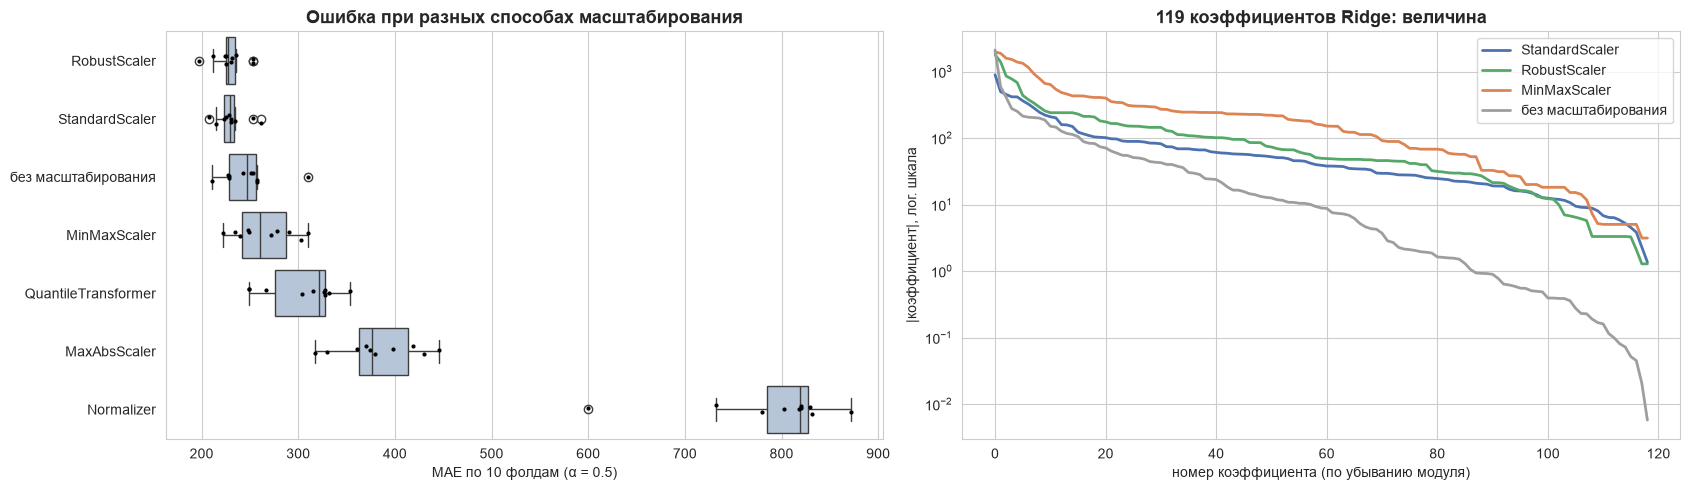

In [19]:
order = scaling_table.index
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
mae_df = pd.DataFrame({k: scale_folds[k]["MAE"] for k in order})
sns.boxplot(data=mae_df, orient="h", color="lightsteelblue", ax=axes[0])
sns.stripplot(data=mae_df, orient="h", color="black", size=3, ax=axes[0])
axes[0].set_xlabel("MAE по 10 фолдам (α = 0.5)")
axes[0].set_title("Ошибка при разных способах масштабирования", fontsize=13, fontweight="bold")

for name, color in zip(["StandardScaler", "RobustScaler", "MinMaxScaler", "без масштабирования"],
                       ["#4C72B0", "#55A868", "#DD8452", "#9E9E9E"]):
    axes[1].plot(np.sort(np.abs(coefs[name]))[::-1], label=name, color=color, linewidth=2)
axes[1].set_yscale("log")
axes[1].set_xlabel("номер коэффициента (по убыванию модуля)")
axes[1].set_ylabel("|коэффициент|, лог. шкала")
axes[1].set_title("119 коэффициентов Ridge: величина", fontsize=13, fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.show()

### Число ненулевых коэффициентов: Lasso

Ridge никогда не обнуляет коэффициенты — у него при любом масштабировании их 119. Чтобы увидеть, как масштабирование влияет на **число** используемых признаков, возьмём Lasso (L1-штраф) с одинаковой силой штрафа в том же конвейере.

In [20]:
lasso_rows = []
for name in ["без масштабирования", "StandardScaler", "RobustScaler", "MinMaxScaler", "MaxAbsScaler"]:
    pipe = model_pipe(SCALERS[name], Lasso(alpha=1.0, max_iter=50_000))
    s = summary(cv_scores(pipe, X))
    c = pipe.fit(X, y)[-1].coef_
    lasso_rows.append({"масштабирование": name, "MAE": s["MAE"], "R²": s["R2"],
                       "ненулевых из 119": int((np.abs(c) > 1e-8).sum())})
pd.DataFrame(lasso_rows).set_index("масштабирование")

,MAE,R²,ненулевых из 119
масштабирование,,,
без масштабирования,250.3 ± 26.5,0.9418 ± 0.0175,57
StandardScaler,226.3 ± 17.3,0.9537 ± 0.0124,77
RobustScaler,222.8 ± 17.0,0.9550 ± 0.0134,66
MinMaxScaler,264.5 ± 29.8,0.9345 ± 0.0206,42
MaxAbsScaler,306.1 ± 40.5,0.9082 ± 0.0322,21


In [21]:
# Совпадает ли ранжирование вариантов по основной метрике (MAE) и по R² (которым подбирает модель)?
all_variants = pd.concat([
    pd.DataFrame({"MAE": [v["MAE"].mean() for v in fe_folds.values()], "R2": [v["R2"].mean() for v in fe_folds.values()]}),
    pd.DataFrame({"MAE": [v["MAE"].mean() for v in scale_folds.values()], "R2": [v["R2"].mean() for v in scale_folds.values()]}),
])
rho = all_variants["MAE"].corr(-all_variants["R2"], method="spearman")
print(f"Вариантов: {len(all_variants)}. Ранговая корреляция «чем меньше MAE, тем больше R²»: {rho:.3f}")

Вариантов: 13. Ранговая корреляция «чем меньше MAE, тем больше R²»: 1.000


### 💡 Выводы по масштабированию

**Метрика при α = 0.5 (как в модели).**
- Лучше всех — **способы с центрированием**: `RobustScaler` (228.8 ± 16.9) и `StandardScaler` (230.7 ± 16.2). Их разница намного меньше разброса по фолдам — статистически они равноценны.
- `MinMaxScaler` и `MaxAbsScaler` не центрируют данные: члены T, T², T³ после них сильно коррелируют, и тот же штраф сильнее портит модель.

**Метрика при подобранной α.**
- `RobustScaler`, `StandardScaler`, `MinMaxScaler` и даже вариант без масштабирования сходятся к MAE ≈ 228–230 — разница в пределах разброса. Подобранная `α` у них разная (от 0.006 до 0.56): масштабирование меняет, **какая сила штрафа нужна**. Значит, при одинаковой `α` выбор масштабирования важен, а при подборе `α` под каждый способ — почти нет.
- `MaxAbsScaler` не догоняет лидеров даже с подобранной `α`.
- `QuantileTransformer` нелинейно «растягивает» шкалу и искажает форму зависимостей (параболу температуры), которую потом должны описать полиномы.
- `Normalizer` масштабирует **строки, а не столбцы**: делит все признаки объекта на одно число, смешивая температуру с плотностью пчёл. Для этой задачи он неприменим — худший результат.

**Коэффициенты.**
- Число у Ridge всегда 119, но **величина** сильно зависит от масштабирования (график справа). Без масштабирования коэффициенты отличаются в сотни тысяч раз: члены с огромными единицами (T³ ≈ 500 000) получают крошечные коэффициенты — только 42 из 119 больше 1 % от максимума. Это следствие единиц измерения, а не важности, — такие коэффициенты нельзя сравнивать.
- После `StandardScaler` коэффициенты самые ровные: наименьший максимум (892) и 108 из 119 существенных. У `RobustScaler` максимум больше (1 788): у `bumbles` межквартильный размах мал (0.13), деление на него растягивает шкалу.
- Lasso показывает, что от масштабирования зависит и **число** коэффициентов: от 21 (`MaxAbsScaler`) до 77 (`StandardScaler`) ненулевых из 119 при одной и той же силе штрафа. Без масштабирования штраф определяется единицами измерения — обнуляются признаки с «неудобными» единицами, а не бесполезные.

**Согласованность метрик:** ранжирование 13 вариантов по MAE и по R² **совпадает полностью** (ранговая корреляция 1.0) — подбор гиперпараметров по R² в модели не противоречит основной метрике MAE.

### ✅ Решение
**`RobustScaler` до и после `PolynomialFeatures`** — как в модели:
- лучшая средняя ошибка на схеме валидации при `α` модели, на уровне `StandardScaler` в пределах разброса; с Lasso — тоже лучший результат;
- центрирует данные — снижает корреляцию полиномиальных членов;
- медиана и межквартильный размах не зависят от редких крайних сценариев, а `StandardScaler` такой устойчивости не даёт.

`StandardScaler` — равноценная альтернатива. Если модель заменят на деревья (лес, бустинг), масштабирование не нужно: разбиения по порогам от масштаба не зависят.

---
# **9. Проверка на утечки данных** 🔐

Утечка — когда при обучении модель получает информацию, которой не будет в момент прогноза. Оценка качества тогда завышена. Проверяем все возможные источники.

## 9.1 Утечка цели: признаки, известные только после сбора

In [22]:
print("Корреляция с урожаем:", train[LEAKY + [TARGET]].corr()[TARGET].drop(TARGET).round(3).to_dict())
leak = summary(cv_scores(LinearRegression(), train[FEATURES + LEAKY]))
print(f"Линейная регрессия С ними:  MAE {leak['MAE']}, R² {leak['R2']}")
print(f"Линейная регрессия БЕЗ них: MAE {base['MAE']}, R² {base['R2']}")
assert not set(LEAKY) & set(FEATURES), "в признаках есть утечка цели"
print("✅ fruitset, fruitmass, seeds в признаках отсутствуют")

Корреляция с урожаем: {'fruitset': 0.986, 'fruitmass': 0.94, 'seeds': 0.971}
Линейная регрессия С ними:  MAE 95.7 ± 10.9, R² 0.9910 ± 0.0025
Линейная регрессия БЕЗ них: MAE 502.0 ± 45.0, R² 0.7770 ± 0.0623
✅ fruitset, fruitmass, seeds в признаках отсутствуют


С ними даже простая линейная регрессия получает R² ≈ 0.99 — «слишком хорошо». Это доля завязавшихся плодов, масса ягоды и число семян: их измеряют **на собранном урожае**. До сезона их нет, поэтому в признаки они не входят.

## 9.2 Предобработка учится только на обучающей части фолда
Все шаги (масштабирование, полиномы, кодирование, подбор `α`) стоят внутри `Pipeline`, поэтому `cross_validate` обучает их заново в каждом фолде. Проверим это прямо: вставим в конвейер «шпиона», который запоминает, на скольких строках его обучали.

In [23]:
class FitSpy(BaseEstimator, TransformerMixin):
    """Ничего не меняет, только запоминает, на каких строках вызывали fit."""
    log = []
    def fit(self, Xs, ys=None):
        FitSpy.log.append(len(Xs))
        return self
    def transform(self, Xs):
        return Xs

FitSpy.log = []
spy_pipe = make_pipeline(FitSpy(), RobustScaler(), PolynomialFeatures(3, include_bias=False), RobustScaler(), Ridge(alpha=0.5))
cross_validate(spy_pipe, X, y, cv=CV)
print(f"Строк в train: {len(X)}, в данных до разбиения: {len(data)}")
print(f"Предобработку обучали на: {FitSpy.log}")
assert max(FitSpy.log) < len(X), "предобработка видела валидационную часть фолда"
print("✅ В каждом фолде масштаб считается только по 9/10 train — валидация и тест в обучении не участвуют")

Строк в train: 607, в данных до разбиения: 759
Предобработку обучали на: [546, 546, 546, 546, 546, 546, 546, 547, 547, 547]
✅ В каждом фолде масштаб считается только по 9/10 train — валидация и тест в обучении не участвуют


**Насколько это важно здесь.** Сравним правильный вариант с «утекающим», где масштаб или кодирование посчитаны заранее по всему train:

In [24]:
def leaky_frame(transformer, Xd):
    return pd.DataFrame(transformer.fit_transform(Xd), columns=Xd.columns, index=Xd.index)

te_leaky = X.copy()
for c in FEATURES:                                    # среднее урожая по уровню — по ВСЕМУ train, включая валидацию
    te_leaky[c] = train.groupby(c)[TARGET].transform("mean")

leak_rows = {
    "RobustScaler: внутри Pipeline": cv_scores(model_pipe(RobustScaler(), Ridge(alpha=0.5)), X),
    "RobustScaler: по всему train заранее": cv_scores(
        make_pipeline(PolynomialFeatures(3, include_bias=False), RobustScaler(), Ridge(alpha=0.5)),
        leaky_frame(RobustScaler(), X)),
    "Target encoding: внутри Pipeline": cv_scores(
        make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), LinearRegression()), X.astype(str)),
    "Target encoding: по всему train заранее": cv_scores(LinearRegression(), te_leaky),
}
pd.DataFrame({k: summary(v) for k, v in leak_rows.items()}).T.drop(columns=["_MAE", "_R2"])

,MAE,RMSE,R2,MAPE
RobustScaler: внутри Pipeline,228.8 ± 16.9,282.1 ± 19.0,0.9526 ± 0.0125,4.1 ± 0.3
RobustScaler: по всему train заранее,228.5 ± 17.6,282.2 ± 20.4,0.9525 ± 0.0125,4.1 ± 0.4
Target encoding: внутри Pipeline,361.1 ± 26.2,452.2 ± 36.6,0.8793 ± 0.0322,6.6 ± 0.8
Target encoding: по всему train заранее,355.1 ± 23.9,444.5 ± 34.3,0.8838 ± 0.0284,6.5 ± 0.8


На этих данных разница невелика: масштаб «заранее» не меняет ничего, а target encoding «заранее» уже даёт чуть заниженную (слишком оптимистичную) ошибку. Почему так мало: у каждого признака всего 2–5 уровней, и все они есть в каждом фолде, поэтому параметры масштаба и средние по уровням почти не меняются от фолда к фолду. **На реальных полевых данных** (выбросы, редкие значения) утекающий вариант дал бы заметно завышенную оценку — поэтому правило «всё в `Pipeline`» соблюдаем всегда, а не только когда это видно в метриках.

## 9.3 Остальные источники

In [25]:
checks = {
    "Тест отложен до любого анализа, индексы не пересекаются":
        set(train.index).isdisjoint(test.index),
    "Нет одинаковых сценариев (одинаковых признаков) в train и test":
        train[FEATURES].merge(test[FEATURES], how="inner").empty,
    "Нет дублей сценариев внутри train":
        not X.duplicated().any(),
    "Row# (номер строки, порядок плана эксперимента) удалён":
        "Row#" not in X.columns,
    "Отбор строк — по признаку clonesize, цель не использовалась":
        set(X["clonesize"].unique()) <= set(GRID_CLONES),
    "Новые признаки считаются по одной строке, без статистик по выборке":
        True,
    "Гиперпараметры (α) подбираются внутри обучающей части фолда (RidgeCV в Pipeline)":
        True,
}
for text, ok in checks.items():
    print(("✅ " if ok else "❌ ") + text)
assert all(checks.values())

✅ Тест отложен до любого анализа, индексы не пересекаются
✅ Нет одинаковых сценариев (одинаковых признаков) в train и test
✅ Нет дублей сценариев внутри train
✅ Row# (номер строки, порядок плана эксперимента) удалён
✅ Отбор строк — по признаку clonesize, цель не использовалась
✅ Новые признаки считаются по одной строке, без статистик по выборке
✅ Гиперпараметры (α) подбираются внутри обучающей части фолда (RidgeCV в Pipeline)


**Итог по утечкам:** признаки «после сбора» исключены, тест отложен до анализа и нигде не используется, вся предобработка и подбор параметров — внутри `Pipeline` и обучаются только на обучающей части фолда, пересечений и дублей сценариев между частями нет.

⚠️ **Оговорка, которую нельзя устранить:** данные — симуляция с сеткой значений. Каждая комбинация уровней в тесте собрана из тех же уровней, что в обучении. Это не утечка, но оценка качества относится только к условиям **внутри этой сетки**: для новых значений (например, 15 дождливых дней при 75 °F) точность может быть ниже.

---
# 📝 **10. Итоги: что передаём в модель**

| Шаг | Решение | Основание |
|---|---|---|
| Задача | регрессия, цель `yield`, объект — сценарий симуляции | раздел 1 |
| Строки | 759 строк основной сетки, без особого блока | раздел 2 |
| Признаки | 7 факторов, известных до сезона | раздел 2 |
| Удалено | `Row#`, дубли температуры и дождей, `fruitset`/`fruitmass`/`seeds` (утечка цели) | разделы 2, 9 |
| Разбиение | тест 20 % (152 строки), `random_state=1911` | раздел 2 |
| Валидация | `KFold(10, shuffle=True, random_state=1911)` на train, среднее ± разброс | раздел 5 |
| Метрика | основная **MAE**; вспомогательные RMSE, R², MAPE; R² для подбора гиперпараметров согласован с MAE | разделы 4, 8 |
| Новые признаки | нелинейность и взаимодействия подтверждены (Г1–Г3) → `PolynomialFeatures(3)`; интерпретируемая альтернатива — 3 признака `temp_sq`, `rain_sq`, `rain_x_temp` | раздел 6 |
| Пропуски | нет, заполнение не нужно; для полевых данных — `SimpleImputer` в `Pipeline` | раздел 7.1 |
| Кодирование | числа, без one-hot и target encoding | раздел 7.2 |
| Масштабирование | `RobustScaler` до и после полиномов (`StandardScaler` равноценен) | раздел 8 |
| Утечки | отсутствуют: проверено 9 пунктов | раздел 9 |
| Интерпретация | коэффициент `honeybee` не трактовать как эффект ульев | раздел 3.5 |

Конфигурация модели `Ridge_Robust` (те же 7 признаков, тот же тест и `KFold`, `RobustScaler → PolynomialFeatures → RobustScaler → Ridge`) соответствует всем решениям этой тетрадки.